# Controlled recovery: 400 cases, two policies, three repetitions

The figures follow the same recovery chain as the paper: a failed artifact check, candidate localization, a dependency closure, synchronized file/history recovery, and live SWE-agent repair.

The completed experiment has 2,400 runs. Cost comparisons use the 1,186 mutually successful case/repetition pairs; accuracy uses all outcomes. Case bootstrap samples carry the repetitions of each original case. The exported input is `review/system-micro-results-20261031/runs.csv`; its source hashes and final audit are adjacent to it.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image, Markdown
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "paper/main.tex").is_file())
sys.path.insert(0, str(ROOT))
from motivation.plot_system_micro_final import setup, load, recovery, localization, phases
setup()
rows, report = load()
assert report["audit"]["audit_passed"]
assert len(rows) == 2400
print(f"Runs: {len(rows)}; successful pairs: {report['statistics']['comparison']['pairs']}")
print(json.dumps(report["statistics"]["comparison"], indent=2))

Runs: 2400; successful pairs: 1186
{
  "pairs": 1186,
  "cases": 400,
  "bootstrap_samples": 20000,
  "total_tokens": {
    "causal_mean": 145357.54384485667,
    "temporal_mean": 464581.95278246206,
    "saving_pct": 68.71218458351964,
    "ci95_pct": [
      65.41083163126025,
      71.75996866813306
    ]
  },
  "full_wall_s": {
    "causal_mean": 233.69214418043768,
    "temporal_mean": 303.8697478146983,
    "saving_pct": 23.094633190354763,
    "ci95_pct": [
      18.182508048903674,
      27.70722809703271
    ]
  },
  "model_wall_s": {
    "causal_mean": 85.27669233334676,
    "temporal_mean": 285.89605881217426,
    "saving_pct": 70.17213434573047,
    "ci95_pct": [
      66.74980618656248,
      73.2921374718038
    ]
  }
}


## Recovery cost along the three sweeps

Red squares show AgentTX; orange crosses show temporal rollback. The upper row uses actual API tokens, and the lower row includes execution/recording, recovery, model repair and verification. Points average per-case means on successful pairs. Shaded bands use 4,000 paired case-bootstrap draws. The paper's aggregate savings use 20,000 draws and the ratio of summed costs.

As the dependency closure grows, the repair sets converge. At dependency value one, candidate validation increases AgentTX's total time.

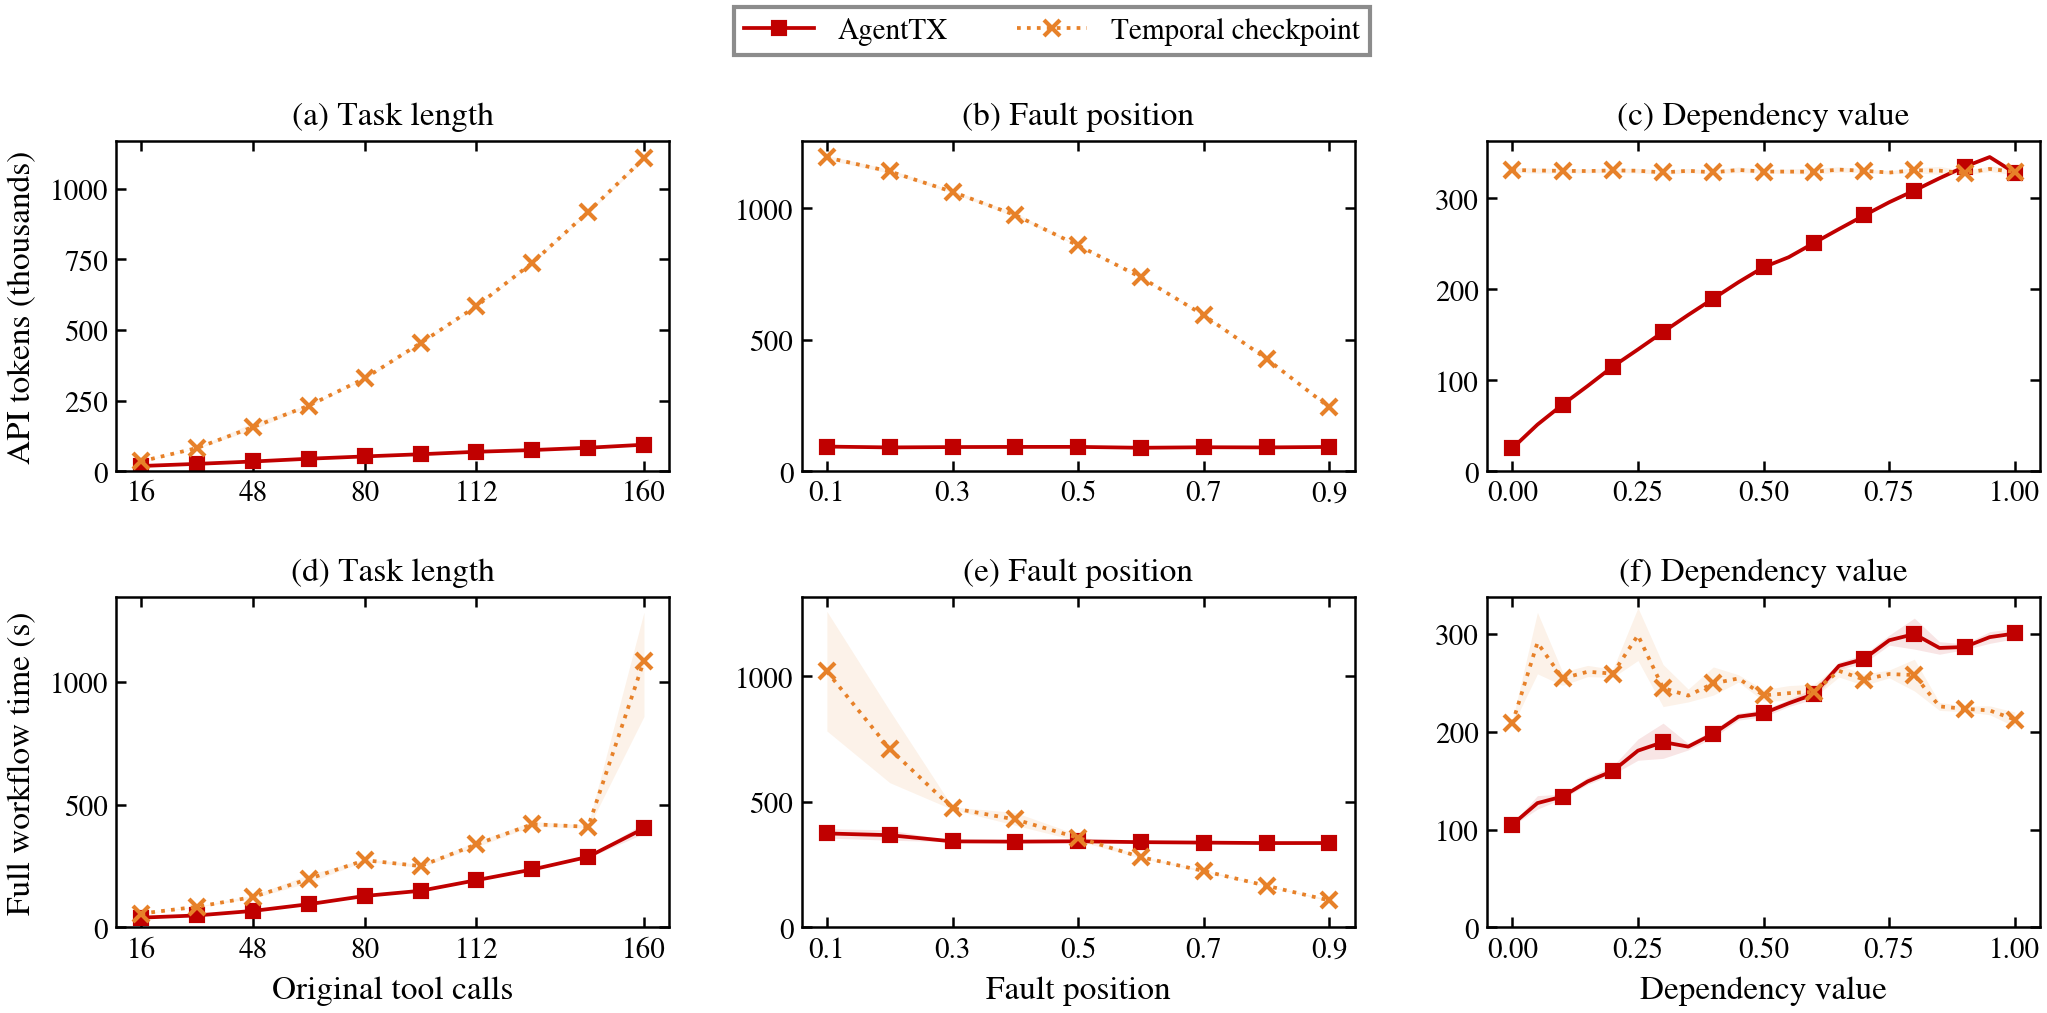

In [2]:
fig = recovery(rows)
display(Image(filename=str(ROOT / "motivation/FIG-System-Micro-Recovery.png")))
plt.close(fig)

## Localization and recovery accuracy

Candidate ranking is the order before isolated validation. The final selected root and closure are scored against the injected fault and generator dependencies. The right panel counts isolated validation probes for AgentTX and public boundary checks for temporal rollback.

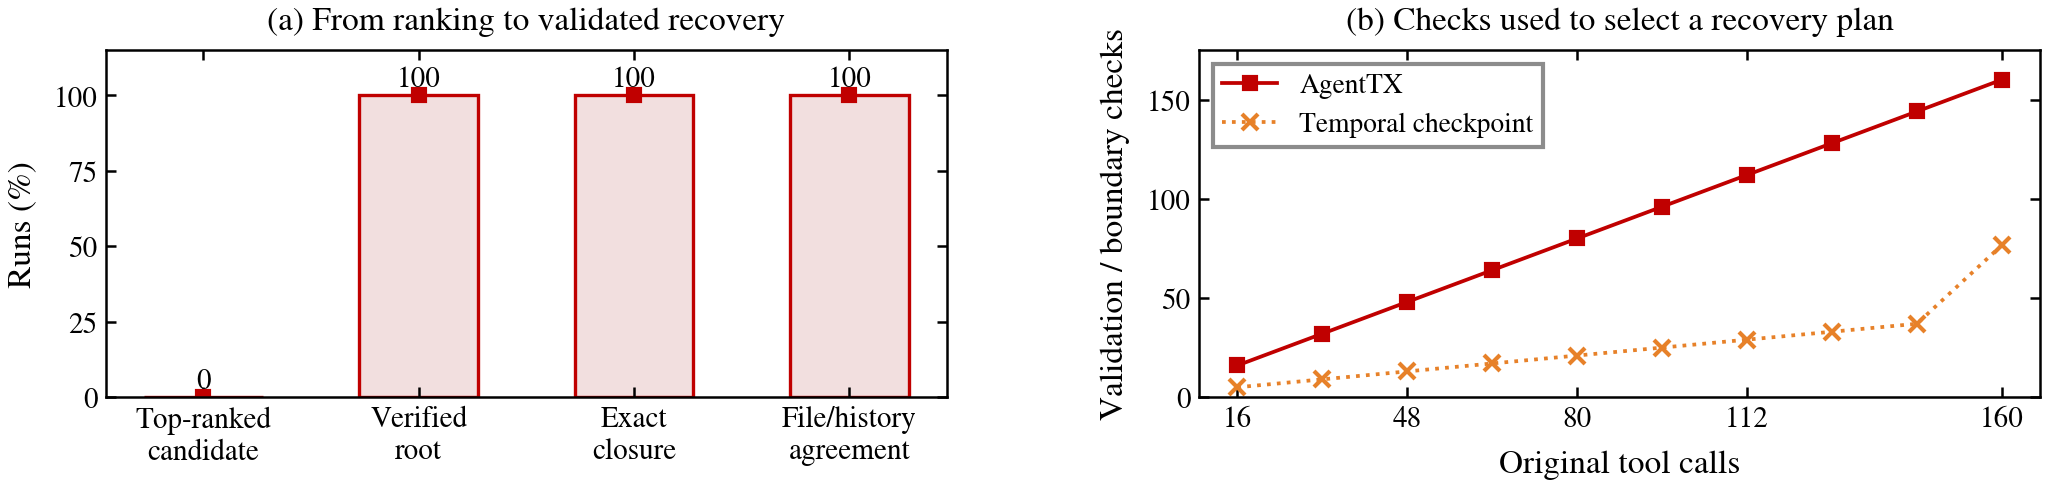

In [3]:
fig = localization(rows, report)
display(Image(filename=str(ROOT / "motivation/FIG-System-Micro-Localization.png")))
plt.close(fig)

## Time spent in the recovery workflow

All runs contribute to the stage means. Execution and recording includes the original operation, tracing, snapshots and ledger updates. Discovery and recovery includes candidate validation or temporal boundary checks. These measurements describe the workflow stages; the original recording time includes useful program execution.

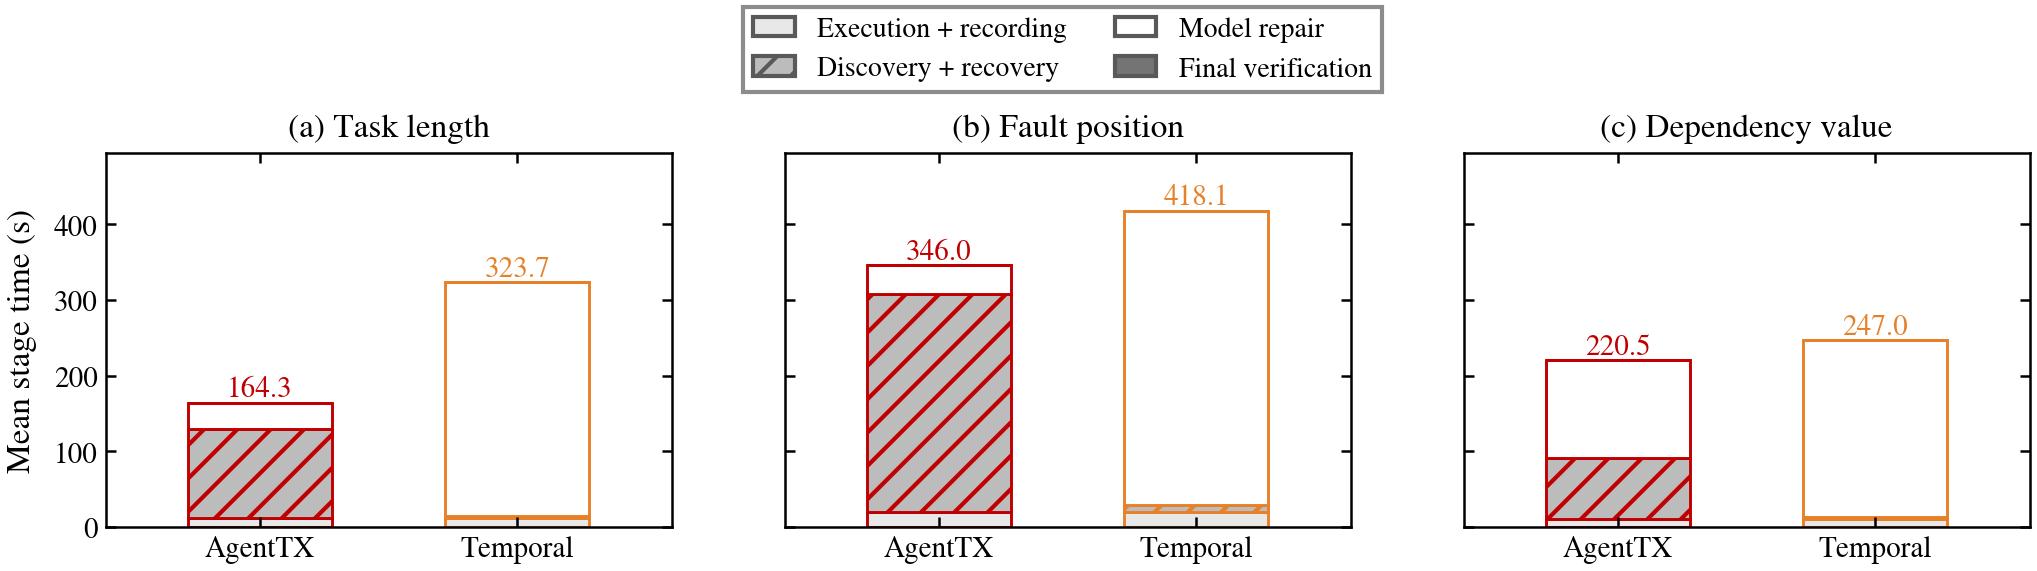

In [4]:
fig = phases(rows)
display(Image(filename=str(ROOT / "motivation/FIG-System-Micro-Phases.png")))
plt.close(fig)

## Reproduction

Run the cells from the repository root or `motivation/`. The plotting functions are editable in `motivation/plot_system_micro_final.py`. They overwrite the same PDF/PNG names under `motivation/` and `paper/img/`.

To regenerate the compact analysis from the completed experiment:

```bash
python experiments/scripts/analyze_system_micro_final.py
```

That command reads the result files listed by `cells.json`, checks the completed audit, exports all 2,400 outcomes, and resamples the original cases. It does not invoke a model.